In [17]:
import sys
import os
import json
import numpy as np
import scipy as sp

sys.path.append(os.path.join(os.getcwd(), '../../src/'))
from utils_mouse import read_utils

sys.path.append(os.path.join(os.getcwd(), '../../../mouse-control/src'))
from utils_mouse_control import read_utils as read_utils_control

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils
from utils import train_utils
from utils import analysis_utils
from models import model_utils

In [18]:
import importlib
importlib.reload(read_utils)
importlib.reload(read_utils_control)
importlib.reload(analysis_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)

<module 'utils.train_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/utils/train_utils.py'>

In [4]:
# file_ids = list(range(0, 12+1))
file_ids = [2]

organism = 'mouse'
model_variant = 'ns'

In [11]:
path = os.path.join(read_utils.get_data_path(), '6163622/sessions')
filenames = [read_utils.get_filename(read_utils.get_filepath(path, file_id)) for file_id in file_ids]

# scores

In [12]:
def assemble(boms_scores_per_neuron, hgms_scores_per_neuron):
	neurons_labels = [scores_per_neuron[0].columns for scores_per_neuron in hgms_scores_per_neuron]

	boms_scores_per_neuron = [np.array([split.values[0] for split in scores]) for scores in boms_scores_per_neuron]
	hgms_scores_per_neuron = [np.array([split.values[0] for split in scores]) for scores in hgms_scores_per_neuron]

	neuron_scores = dict()
	boms_scores_per_neuron_avg = [np.mean(scores, axis=0) for scores in boms_scores_per_neuron]
	hgms_scores_per_neuron_avg = [np.mean(scores, axis=0) for scores in hgms_scores_per_neuron]
	for label_list, score_bom_list, score_hgm_list in zip(neurons_labels, boms_scores_per_neuron_avg, hgms_scores_per_neuron_avg):
		sort_indices = np.argsort(score_hgm_list)[::-1]
		label_list = label_list[sort_indices]
		score_bom_list = score_bom_list[sort_indices]
		score_hgm_list = score_hgm_list[sort_indices]

		for i in range(len(label_list)):
			label = label_list[i]
			if label != '' and label[-1] != '_':
				score_bom_new, score_hgm_new = np.array(score_bom_list[i]), np.array(score_hgm_list[i])
				if len(score_hgm_new.shape) == 0:
					score_bom_new = score_bom_new.reshape(1, 1)
					score_hgm_new = score_hgm_new.reshape(1, 1)
				if label not in neuron_scores.keys():
					neuron_scores[label] = (score_bom_new, score_hgm_new)
				else:
					score_bom_prev, score_hgm_prev = neuron_scores[label]
					neuron_scores[label] = (np.vstack([score_bom_prev, score_bom_new]), np.vstack([score_hgm_prev, score_hgm_new]))

	return neuron_scores

In [20]:
scores_per_shuffle = list()
for shuffle_id in range(100):
	scores_per_dataset = list()
	for filename in filenames:
		((bom_spn, _, _, _, _, _, _),
		 (hgm_spn, _, _, _, _, _, _)) = analysis_utils.read_scores(read_utils_control.get_model_path(shuffle_id), filename, model_variant, manual=False)
		scores_per_dataset.append((bom_spn, hgm_spn))
	bom_spns, hgm_spns = zip(*scores_per_dataset)
	scores_per_shuffle.append([bom_spns, hgm_spns])

neuron_scores_per_shuffle = [assemble(*scores_per_shuffle[i]) for i in range(100)]
scores_per_shuffle = None

In [23]:
scores_per_dataset_actual = list()
for filename in filenames:
	((bom_spn, _, _, _, _, _, _),
	 (hgm_spn, _, _, _, _, _, _)) = analysis_utils.read_scores(read_utils.get_model_path(), filename, model_variant, manual=False)
	scores_per_dataset_actual.append((bom_spn, hgm_spn))
bom_spns_actual, hgm_spns_actual = zip(*scores_per_dataset_actual)

neuron_scores_actual = assemble(bom_spns_actual, hgm_spns_actual)
scores_per_dataset_actual = None

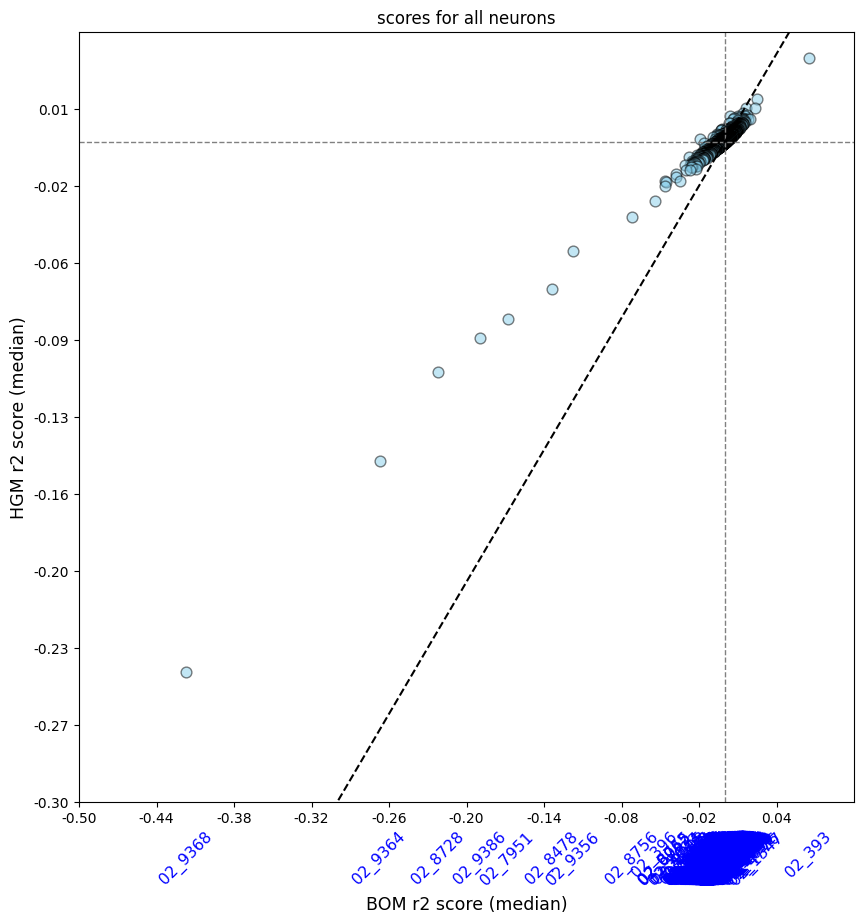

In [28]:
plot_utils.plot_performance_plot(
	neuron_scores_actual, None,
	title='scores for all neurons', limits=(-0.5, 0.1, -0.3, 0.05), force_medians=False
)

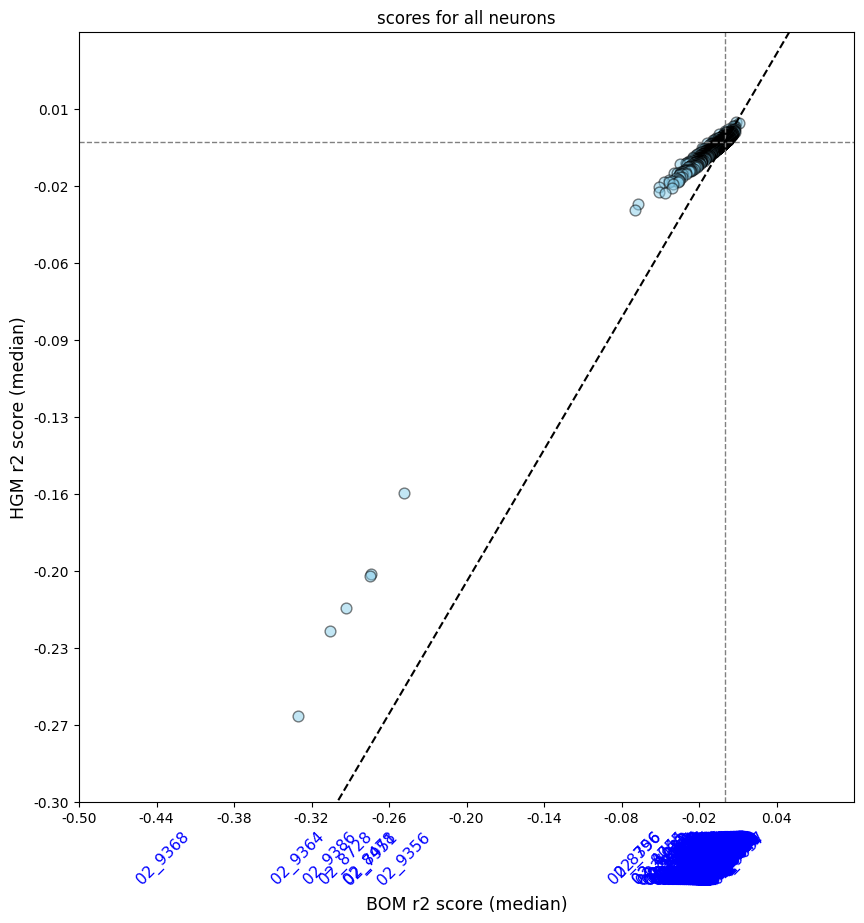

In [29]:
plot_utils.plot_performance_plot(
	neuron_scores_per_shuffle[0], None,
	title='scores for all neurons', limits=(-0.5, 0.1, -0.3, 0.05), force_medians=False
)

In [30]:
import numpy as np
from typing import Callable, Dict, Iterable, List, Tuple, Union

def compute_neuron_percentiles(
    neuron_scores_actual: Dict[str, Tuple[np.ndarray, np.ndarray]],
    neuron_scores_per_shuffle: Iterable[Dict[str, Tuple[np.ndarray, np.ndarray]]],
    model: Union[str, int] = 'hgm',
    agg_func: Callable[[np.ndarray], float] = None,
) -> Dict[str, float]:
    """
    For each neuron key in `neuron_scores_actual`, compute the percentile of the actual score
    relative to the distribution built from `neuron_scores_per_shuffle`.

    Args:
      neuron_scores_actual: dict mapping neuron_label -> (bom_array, hgm_array)
        (matches the structure produced by your `assemble` function).
      neuron_scores_per_shuffle: iterable (list) of shuffle dicts,
        each mapping neuron_label -> (bom_array, hgm_array).
      model: 'hgm' or 'bom' or 0/1 integer selecting the tuple element.
      agg_func: function to reduce an array to a scalar (default: np.nanmean of flattened array).

    Returns:
      dict mapping neuron_label -> percentile (0..100) where percentile p means
      actual > p% of shuffle values; ties are handled using mid-rank:
      (count_less + 0.5 * count_equal) / N * 100.
    """
    # choose index 0=bom, 1=hgm
    if isinstance(model, str):
        model = model.lower()
        if model == 'bom':
            model_index = 0
        elif model == 'hgm':
            model_index = 1
        else:
            raise ValueError("model must be 'bom' or 'hgm' (or 0/1).")
    else:
        model_index = int(model)

    if agg_func is None:
        def agg_func_default(x: np.ndarray) -> float:
            # flatten and take nanmean by default
            if x is None:
                return np.nan
            x = np.asarray(x)
            if x.size == 0:
                return np.nan
            return float(np.nanmean(x))
        agg_func = agg_func_default

    percentiles = {}
    # Convert shuffles to list to iterate multiple times if needed
    shuffles_list = list(neuron_scores_per_shuffle)

    for label, actual_pair in neuron_scores_actual.items():
        try:
            actual_arr = actual_pair[model_index]
        except Exception:
            percentiles[label] = np.nan
            continue

        actual_value = agg_func(actual_arr)

        # Build distribution across shuffles for this neuron label
        dist_values = []
        for shuffle_dict in shuffles_list:
            if label not in shuffle_dict:
                # some shuffles might not contain this neuron -> skip
                continue
            shuffle_arr = shuffle_dict[label][model_index]
            val = agg_func(shuffle_arr)
            # If agg returns nan (e.g. empty), skip
            if np.isnan(val):
                continue
            dist_values.append(val)

        if len(dist_values) == 0 or np.isnan(actual_value):
            percentiles[label] = np.nan
            continue

        dist = np.asarray(dist_values)
        count_less = np.sum(dist < actual_value)
        count_equal = np.sum(dist == actual_value)
        N = len(dist)

        # mid-rank percentile
        pct = (count_less + 0.5 * count_equal) / N * 100.0
        percentiles[label] = float(pct)

    return percentiles

In [32]:
# compute HGM percentiles (default agg: mean of flattened array)
percentiles_hgm = compute_neuron_percentiles(
    neuron_scores_actual,
    neuron_scores_per_shuffle,
    model='hgm'
)

# compute BOM percentiles
percentiles_bom = compute_neuron_percentiles(
    neuron_scores_actual,
    neuron_scores_per_shuffle,
    model='bom'
)

# print top 10 neurons by HGM percentile
top10 = sorted(percentiles_hgm.items(), key=lambda kv: kv[1] if not np.isnan(kv[1]) else -1, reverse=True)[:]
for label, pct in top10:
    print(f"{label}: {pct:.1f} percentile")

02_393: 100.0 percentile
02_1347: 100.0 percentile
02_8040: 100.0 percentile
02_4776: 100.0 percentile
02_2844: 100.0 percentile
02_4043: 100.0 percentile
02_1896: 100.0 percentile
02_3712: 100.0 percentile
02_1364: 100.0 percentile
02_2566: 100.0 percentile
02_2856: 100.0 percentile
02_1348: 100.0 percentile
02_2314: 100.0 percentile
02_048: 100.0 percentile
02_8883: 100.0 percentile
02_2659: 100.0 percentile
02_6242: 100.0 percentile
02_4012: 100.0 percentile
02_5000: 100.0 percentile
02_9082: 100.0 percentile
02_9037: 100.0 percentile
02_4028: 100.0 percentile
02_041: 100.0 percentile
02_9242: 100.0 percentile
02_5277: 100.0 percentile
02_1337: 100.0 percentile
02_7287: 100.0 percentile
02_5249: 100.0 percentile
02_034: 100.0 percentile
02_9235: 100.0 percentile
02_7792: 100.0 percentile
02_3845: 100.0 percentile
02_6635: 100.0 percentile
02_5464: 100.0 percentile
02_100: 100.0 percentile
02_2005: 100.0 percentile
02_2217: 100.0 percentile
02_9107: 100.0 percentile
02_044: 100.0 per

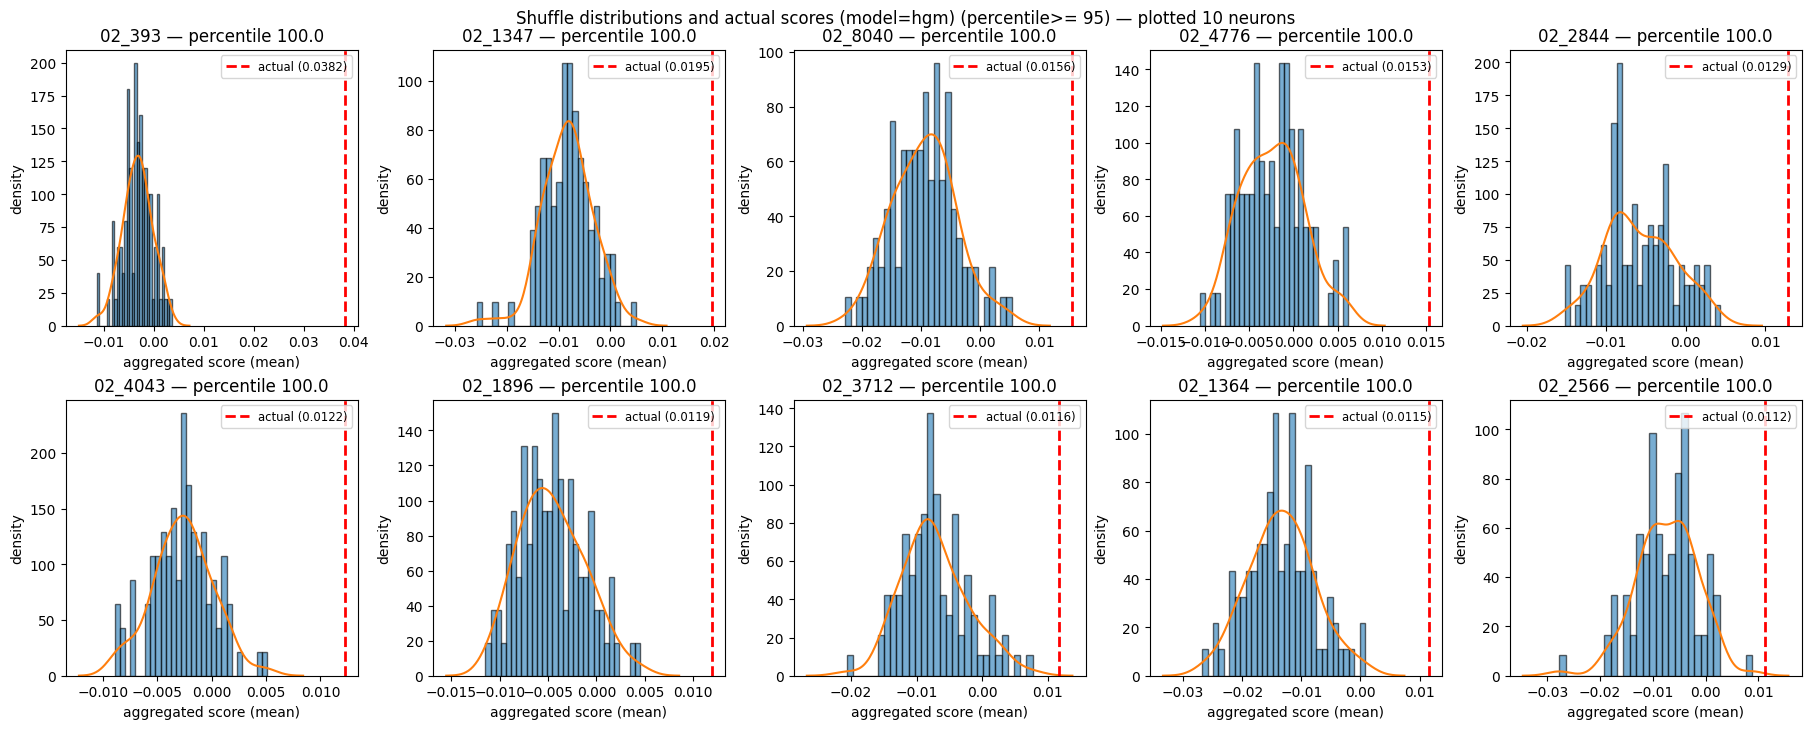

Plotted neurons: ['02_393', '02_1347', '02_8040', '02_4776', '02_2844', '02_4043', '02_1896', '02_3712', '02_1364', '02_2566']


In [36]:
# Plot distributions for neurons: histogram of shuffle values + actual value marker
import matplotlib.pyplot as plt

# optional: nicer KDE if seaborn present
try:
    import seaborn as sns
    _HAS_SNS = True
except Exception:
    _HAS_SNS = False
    from scipy.stats import gaussian_kde

def agg_default(x):
    if x is None:
        return np.nan
    a = np.asarray(x)
    if a.size == 0:
        return np.nan
    return float(np.nanmean(a))

def compute_dist_and_percentile(label, neuron_scores_actual, neuron_scores_per_shuffle,
                                model_index=1, agg_func=agg_default):
    # get actual scalar
    if label not in neuron_scores_actual:
        return None, None, "missing_actual"
    actual_arr = neuron_scores_actual[label][model_index]
    actual_val = agg_func(actual_arr)
    # gather shuffle values
    dist = []
    for shuffle_dict in neuron_scores_per_shuffle:
        if label not in shuffle_dict:
            continue
        val = agg_func(shuffle_dict[label][model_index])
        if np.isnan(val):
            continue
        dist.append(val)
    if len(dist) == 0 or np.isnan(actual_val):
        return np.array(dist), actual_val, "insufficient_shuffles"
    dist = np.asarray(dist)
    # mid-rank percentile
    count_less = np.sum(dist < actual_val)
    count_equal = np.sum(dist == actual_val)
    N = len(dist)
    pct = (count_less + 0.5 * count_equal) / N * 100.0
    return dist, actual_val, pct

def plot_first_n_neurons(neuron_scores_actual, neuron_scores_per_shuffle,
                         model='hgm', agg_func=agg_default, n=10,
                         neuron_labels=None, bins=30, figsize=(18, 7), threshold=95):
    """
    Plot neurons according to selection logic:
      - If `neuron_labels` is provided, plot those (up to n).
      - Else if `threshold` is not None, compute percentiles and select neurons with
        percentile >= threshold. If that selection is non-empty, plot up to `n` of them
        (sorted by percentile desc). If selection is empty, plot ALL neurons (no cap).
      - Else (threshold is None), fall back to original behavior: choose top-n by actual value.

    Args:
      threshold: percentile cutoff (0-100). Use None to disable threshold selection.
    """
    # keep a copy of the original model argument for percentile computation
    original_model_arg = model

    # determine model index (and normalize `model` for later use)
    if isinstance(model, str):
        model = model.lower()
        if model == 'bom':
            model_index = 0
        elif model == 'hgm':
            model_index = 1
        else:
            raise ValueError("model must be 'bom' or 'hgm'")
    else:
        model_index = int(model)

    # Determine which neuron labels to plot
    if neuron_labels is None:
        if threshold is not None:
            # compute percentiles for all neurons
            percentiles = compute_neuron_percentiles(
                neuron_scores_actual, neuron_scores_per_shuffle,
                model=original_model_arg, agg_func=agg_func
            )
            # select labels meeting the threshold
            selected = [label for label, pct in percentiles.items() if not np.isnan(pct) and pct >= threshold]
            # sort selected by percentile descending (so most significant first)
            selected.sort(key=lambda L: percentiles[L], reverse=True)

            if len(selected) > 0:
                # cap to n
                chosen = selected[:n]
            else:
                # none meet the threshold -> plot ALL neurons (no cap)
                chosen = list(neuron_scores_actual.keys())
        else:
            # original behavior: choose top-n by actual aggregated value
            entries = []
            for label, pair in neuron_scores_actual.items():
                val = agg_func(pair[model_index])
                entries.append((label, val))
            entries = [e for e in entries if not np.isnan(e[1])]
            entries.sort(key=lambda kv: kv[1], reverse=True)
            chosen = [label for label, _ in entries][:n]
            if len(chosen) < n:
                for label in neuron_scores_actual.keys():
                    if label not in chosen:
                        chosen.append(label)
                    if len(chosen) >= n:
                        break
    else:
        # explicit list provided by user: respect it but cap at n
        chosen = list(neuron_labels)[:n]

    # plotting grid 2 x ceil(n/2) but adapt to actual number chosen
    total_to_plot = len(chosen)
    rows = 2
    cols = int(np.ceil(total_to_plot / rows)) if total_to_plot > 0 else 1
    fig, axes = plt.subplots(rows, cols, figsize=figsize, constrained_layout=True)
    axes = np.array(axes).flatten()

    # if nothing to plot, show message and return
    if total_to_plot == 0:
        fig.text(0.5, 0.5, "No neurons selected to plot.", ha='center', va='center', fontsize=12)
        thresh_msg = f" (percentile>= {threshold})" if threshold is not None else ""
        plt.suptitle(f"Shuffle distributions and actual scores (model={original_model_arg}){thresh_msg} — plotted 0 neurons", y=1.02)
        plt.show()
        return []

    # safe default for loop index
    i = -1

    for i, label in enumerate(chosen):
        ax = axes[i]
        dist, actual_val, pct_or_status = compute_dist_and_percentile(label,
                                                                      neuron_scores_actual,
                                                                      neuron_scores_per_shuffle,
                                                                      model_index=model_index,
                                                                      agg_func=agg_func)
        if isinstance(pct_or_status, str):
            # status message: missing or insufficient
            ax.text(0.5, 0.5, f"{label}\nStatus: {pct_or_status}",
                    ha='center', va='center', transform=ax.transAxes)
            ax.set_title(label)
            ax.set_ylabel("")
            ax.set_xlabel("")
            ax.set_yticks([])
            continue

        pct = pct_or_status
        # histogram
        if len(dist) > 0:
            ax.hist(dist, bins=bins, density=True, alpha=0.6, color='C0', edgecolor='k')
            if _HAS_SNS:
                try:
                    sns.kdeplot(dist, ax=ax, color='C1')
                except Exception:
                    pass
            else:
                # fallback KDE using scipy
                try:
                    kde = gaussian_kde(dist)
                    xs = np.linspace(np.min(dist), np.max(dist), 200)
                    ax.plot(xs, kde(xs), color='C1', lw=1)
                except Exception:
                    pass
        else:
            ax.text(0.5, 0.5, "no shuffle values", ha='center', va='center', transform=ax.transAxes)

        # mark actual value
        ax.axvline(actual_val, color='red', linestyle='--', lw=2, label=f'actual ({actual_val:.3g})')
        title_extra = f" — percentile {pct:.1f}" if not np.isnan(pct) else ""
        ax.set_title(f"{label}{title_extra}")
        ax.legend(loc='upper right', fontsize='small')
        ax.set_xlabel("aggregated score (mean)")
        ax.set_ylabel("density")

    # hide unused axes if any
    if i >= 0:
        for j in range(i+1, len(axes)):
            axes[j].axis('off')

    thresh_msg = f" (percentile>= {threshold})" if threshold is not None else ""
    plt.suptitle(f"Shuffle distributions and actual scores (model={original_model_arg}){thresh_msg} — plotted {total_to_plot} neurons", y=1.02)
    plt.show()
    return chosen

# Example usage: plots the top-10 neurons by actual HGM score
chosen = plot_first_n_neurons(neuron_scores_actual, neuron_scores_per_shuffle, model='hgm', n=10)
print("Plotted neurons:", chosen)

# If you want the literal insertion-order 'first 10 keys' instead, call:
# first10_insertion_order = list(neuron_scores_actual.keys())[:10]
# chosen = plot_first_n_neurons(neuron_scores_actual, neuron_scores_per_shuffle, model='hgm', neuron_labels=first10_insertion_order)